Part A

A.1

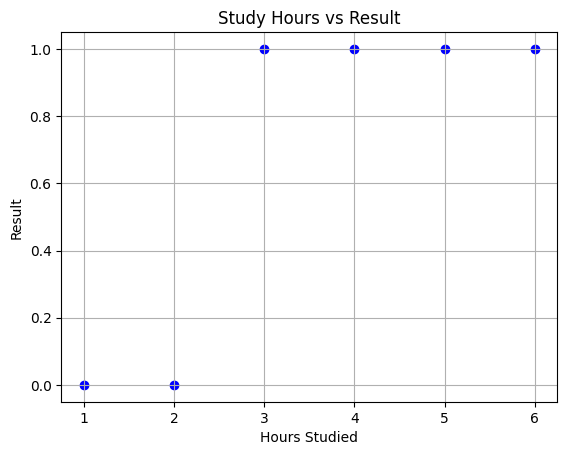

Input Feature (X): Hours Studied
Target Variable (Y): Result


In [1]:
import numpy as np
import matplotlib.pyplot as plt

#1
X = np.array([1, 2, 3, 4, 5, 6])
Y = np.array([0, 0, 1, 1, 1, 1])

#2
plt.scatter(X, Y, color='blue')
plt.xlabel("Hours Studied")
plt.ylabel("Result")
plt.title("Study Hours vs Result")
plt.grid(True)
plt.show()

#3
print("Input Feature (X): Hours Studied")
print("Target Variable (Y): Result")

A.2

In [2]:
#1
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

#2
theta0 = 0
theta1 = 0

#3
z = theta0 + theta1 * X
pred_probs = sigmoid(z)

print(pred_probs)

[0.5 0.5 0.5 0.5 0.5 0.5]


#4
0.5

#5
It converts any real valued score into a probability between 0 and 1.

This allows Logistic Regression to perform binary classification.

A.3

In [3]:
#1
def log_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1-epsilon)

    return -np.mean(
        y_true*np.log(y_pred) +
        (1-y_true)*np.log(1-y_pred)
    )

cost = log_loss(Y, pred_probs)

#2
print("Initial Cost =", cost)

Initial Cost = 0.6931471805599453


#3
Better Prediction.

Predicted probabilities are closer to actual labels.

#4
Loss becomes very large.

#5
It measures model error and guides Gradient Descent.

A.4

In [4]:
#1
theta0 = 0
theta1 = 0

alpha = 0.1
iterations = 1000

m = len(X)

cost_history = []

#4
for i in range(iterations):

    z = theta0 + theta1 * X
    h = sigmoid(z)

#2
    d_theta0 = (1/m) * np.sum(h - Y)
    d_theta1 = (1/m) * np.sum((h - Y) * X)

#3
    theta0 -= alpha * d_theta0
    theta1 -= alpha * d_theta1

#5
    cost = log_loss(Y, h)
    cost_history.append(cost)

#6
print("Final theta0 =", theta0)
print("Final theta1 =", theta1)

Final theta0 = -4.862769639865572
Final theta1 = 2.0713320531008033


Task 2 – Observe Convergence

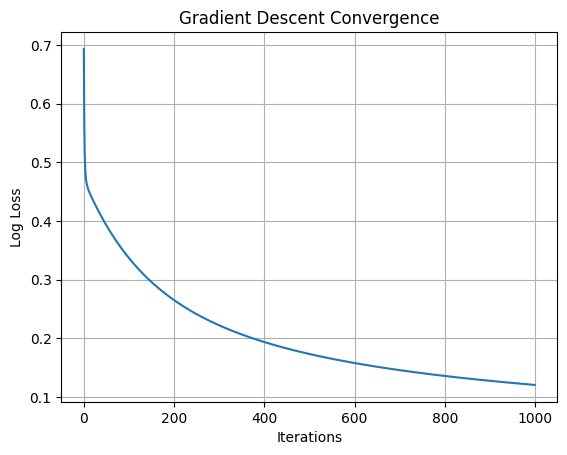

In [5]:
#1
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Log Loss")
plt.title("Gradient Descent Convergence")
plt.grid(True)
plt.show()

#2
Loss decreases gradually.

#3
Model is approaching the minimum cost.

#4
Loss may oscillate or diverge.

#5
Training becomes very slow.


A.5

In [6]:
#1
def predict_probability(x):
    z = theta0 + theta1 * x
    return sigmoid(z)

def predict_class(x, threshold=0.5):
    prob = predict_probability(x)

    if prob >= threshold:
        return 1
    else:
        return 0
#2
x_new = 2.5

prob = predict_probability(x_new)
pred = predict_class(x_new)

#3
print("Probability =", prob)
print("Class =", pred)

#4
pred_7 = predict_class(x_new, threshold=0.7)
print("Class with 0.7 threshold =", pred_7)

Probability = 0.5782419308718891
Class = 1
Class with 0.7 threshold = 0


Yes, the prediction changes. At a threshold of 0.5, the student is predicted to Pass (1), but at a threshold of 0.7, the student is predicted to Fail (0) because the predicted probability is approximately 0.578.

#5
The classification threshold is the probability cutoff used to decide whether a prediction belongs to Class 1 or Class 0.Changing the threshold changes the classification decision boundary, even though the learned model parameters remain unchanged.



A.6

In [7]:
import numpy as np
from sklearn.linear_model import LogisticRegression

# Dataset
X = np.array([[1], [2], [3], [4], [5], [6]])
Y = np.array([0, 0, 1, 1, 1, 1])

# Train model
model = LogisticRegression()

model.fit(X, Y)

# Predict for 2.5 hours
x_new = np.array([[2.5]])

probability = model.predict_proba(x_new)[0][1]
prediction = model.predict(x_new)[0]

print("Probability =", probability)
print("Predicted Class =", prediction)

print("Intercept (theta0) =", model.intercept_[0])
print("Coefficient (theta1) =", model.coef_[0][0])

Probability = 0.5259872612927811
Predicted Class = 1
Intercept (theta0) = -2.595842711667746
Coefficient (theta1) = 1.0799542039175742


#3
The Scikit-Learn prediction is very similar to the from-scratch Logistic Regression implementation. Both models predict that a student studying 2.5 hours is likely to pass (Class 1).

#4
No. The learned parameter values are usually not exactly the same because Scikit-Learn uses advanced optimization methods and regularization by default, while the from-scratch model uses Gradient Descent with a chosen learning rate and number of iterations. However, the predictions are generally very similar.

Part B

B.1

In [8]:
#1
import numpy as np

X_train = np.array([
    [1,1],
    [2,1.5],
    [2,3],
    [4,5],
    [5,4.5],
    [5,2.5]
])

y_train = np.array([0,0,0,1,1,1])

Q = np.array([4,2])

B.2

In [9]:
def euclidean_distance(p, q):
    return np.sqrt(np.sum((p-q)**2))

distances = []

#3
for i in range(len(X_train)):
    d = euclidean_distance(X_train[i], Q)
    distances.append(d)

for i,d in enumerate(distances):
    print(i,d)

0 3.1622776601683795
1 2.0615528128088303
2 2.23606797749979
3 3.0
4 2.692582403567252
5 1.118033988749895


In [10]:
#4
sorted_indices = np.argsort(distances)

for idx in sorted_indices:
    print(idx, distances[idx], y_train[idx])

5 1.118033988749895 1
1 2.0615528128088303 0
2 2.23606797749979 0
4 2.692582403567252 1
3 3.0 1
0 3.1622776601683795 0


B.3

In [11]:
#1 Set k=3
k = 3

#2 Identify the three nearest observations
k_nearest_indices = sorted_indices[:k]

#3 Display their distances and class labels
print(f"The {k} nearest neighbors to Q are:")
for idx in k_nearest_indices:
    print(f"Index {idx} | Distance: {distances[idx]:.4f} | Class Label: {y_train[idx]}")

#4 Apply majority voting
k_nearest_labels = y_train[k_nearest_indices]

# Using np.unique to count the occurrences of each label
vals, counts = np.unique(k_nearest_labels, return_counts=True)
predicted_class = vals[np.argmax(counts)]

#5 Predict whether student Q will Pass or Fail
print(f"\nMajority Vote Result: {predicted_class}")
if predicted_class == 1:
    print("Prediction: Student Q will Pass (1).")
else:
    print("Prediction: Student Q will Fail (0).")

The 3 nearest neighbors to Q are:
Index 5 | Distance: 1.1180 | Class Label: 1
Index 1 | Distance: 2.0616 | Class Label: 0
Index 2 | Distance: 2.2361 | Class Label: 0

Majority Vote Result: 0
Prediction: Student Q will Fail (0).


B.5

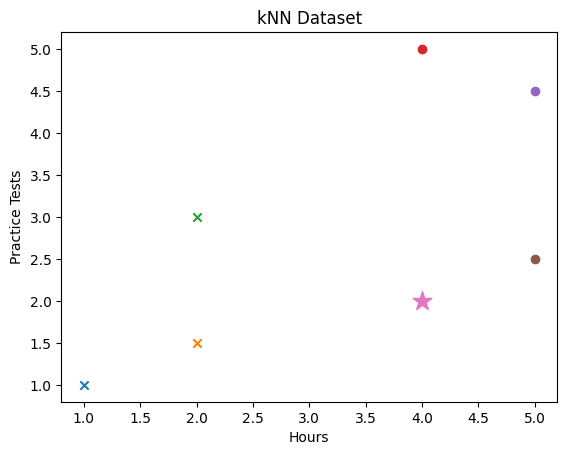

In [12]:
import matplotlib.pyplot as plt

for i in range(len(y_train)):
    if y_train[i] == 0:
        plt.scatter(X_train[i,0], X_train[i,1], marker='x')
    else:
        plt.scatter(X_train[i,0], X_train[i,1], marker='o')

plt.scatter(Q[0], Q[1], marker='*', s=200)

plt.xlabel("Hours")
plt.ylabel("Practice Tests")
plt.title("kNN Dataset")
plt.show()

B.6

In [13]:
def knn_predict(X_train, y_train, query, k):

    #1
    distances = []

    for i in range(len(X_train)):
        d = np.sqrt(np.sum((X_train[i]-query)**2))
        distances.append(d)

    #2,#3
    nearest = np.argsort(distances)[:k]

    #4
    labels = y_train[nearest]

    #5
    prediction = np.bincount(labels).argmax()

    #6
    return prediction

print(knn_predict(X_train, y_train, Q, 3))

0


B.7

In [14]:
from sklearn.neighbors import KNeighborsClassifier

#2
model = KNeighborsClassifier(n_neighbors=3)

#1
model.fit(X_train, y_train)

#3
prediction = model.predict([Q])

print(prediction)

#4
#Scikit-learn prediction = 0
#Same as from-scratch implementation.

[0]


B.8

#1
Annual Income.

#2
Large-scale feature overwhelms smaller-scale features.

#3
Standardization (Z-score scaling).

#4


In [15]:
#4
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the query point Q using the same scaler
# Note: Q needs to be passed as a 2D array, hence [Q]
Q_scaled = scaler.transform([Q])

# Repeat the prediction using your from-scratch function
# Q_scaled[0] extracts the 1D array back for your custom function
pred_scaled = knn_predict(X_train_scaled, y_train, Q_scaled[0], k=3)

print("Prediction with scaled features =", pred_scaled)

Prediction with scaled features = 0


Part c

#1
MSE can create a non-convex optimization surface when it is combined with the sigmoid function. This can make Gradient Descent converge slowly or get stuck at a point that is not the global minimum. In contrast, Log-Loss provides a convex cost surface for this Logistic Regression problem, making the optimization process more stable and reliable. Therefore, Log-Loss is preferred because Gradient Descent can reach the minimum more consistently.

#2
For a spam filter, a false positive means that a legitimate email is incorrectly classified as spam, which can be disruptive to the user. Therefore, the threshold should generally be above 0.5 so that an email is classified as spam only when the model is sufficiently confident. For cancer screening, a false negative means failing to detect a person who may have cancer, which is much more serious than a false positive. Therefore, the threshold should generally be below 0.5 to increase sensitivity and reduce the chance of missing potential cases.

#3
Increasing k in kNN generally reduces variance but increases bias because the prediction is based on a larger group of training points. With a small k, the model follows local patterns closely, making it more sensitive to individual points and noise. As k becomes larger, the decision boundary becomes smoother because predictions are influenced by more neighbours. If k equals the total number of training points, every prediction uses the entire dataset, so the same majority class would be predicted for every query and the decision boundary would become extremely simple.

#4
The claim is incorrect because achieving 100% accuracy on the training set does not mean that a model will perform well on unseen data. With k = 1, kNN can easily memorize the training observations, which can result in overfitting and poor generalization. A model should therefore be evaluated based on how well it performs on unseen data, rather than only on its training accuracy. Logistic Regression may sometimes generalize better because it learns a simpler linear decision boundary instead of relying on individual training observations.

#5
Logistic Regression uses an explicit hypothesis function of the form h(x)=σ(θ0+θ1x), so its decision boundary is determined by a linear equation. Because the learned parameters define a fixed linear relationship between the features and the prediction, the resulting boundary is straight in this lab. kNN does not learn an explicit equation; instead, it predicts a point based on the classes of nearby training observations. Therefore, its decision boundary can bend and become irregular around clusters of training points, depending on the value of k.